<a href="https://colab.research.google.com/github/gyeongee/TIL/blob/main/tensor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch

In [ ]:
ft=torch.FloatTensor([[1,2],
                      [3,4]])
ft

tensor([[1., 2.],
        [3., 4.]])

실수형 값들로 요소가 채워진 것을 확인할 수 있습니다.

In [ ]:
lt=torch.LongTensor([[1,2,],
                     [3,4]])
bt=torch.ByteTensor([[1,2],
                     [3,4]])
print(lt)
print(bt)

tensor([[1, 2],
        [3, 4]])
tensor([[1, 2],
        [3, 4]], dtype=torch.uint8)


In [ ]:
# 임의의 값으로 채워진 원하는 크기의 텐서를 만들어보자
x=torch.FloatTensor(3,2)
x

tensor([[1.6431e-20, 0.0000e+00],
        [0.0000e+00, 0.0000e+00],
        [0.0000e+00, 0.0000e+00]])

3행 2열의 실수형 텐서가 만들어진 것을 알 수 있다.

In [ ]:
print(torch.rand(3, 2))   # 0~1 사이 균등분포 난수
print(torch.randn(3, 2))   # 표준정규분포 난수
print(torch.zeros(3, 2))   # 전부 0

tensor([[0.4000, 0.4951],
        [0.9829, 0.8983],
        [0.5328, 0.0043]])
tensor([[-1.9036,  0.5966],
        [ 0.8677,  1.9198],
        [ 0.8114, -1.3121]])
tensor([[0., 0.],
        [0., 0.],
        [0., 0.]])


### 넘파이 호환

In [ ]:
import numpy as np

x=np.array([[1,2],
            [3,4]])
print(x,type(x))


[[1 2]
 [3 4]] <class 'numpy.ndarray'>


In [ ]:
# 넘파이를 파이토치 텐서로 변경하기
x=torch.from_numpy(x)
print(x,type(x))

tensor([[1, 2],
        [3, 4]]) <class 'torch.Tensor'>


In [ ]:
# 파이토치 텐서를 넘파이로 바꾸기
x=x.numpy()
print(x,type(x))

[[1 2]
 [3 4]] <class 'numpy.ndarray'>


### 텐서 타입 변경

In [ ]:
ft.long()
ft

tensor([[1., 2.],
        [3., 4.]])

In [ ]:
lt.float()
lt

tensor([[1, 2],
        [3, 4]])

### 텐서 크기 구하기

In [ ]:
x=torch.FloatTensor([[[1,2,],
                      [3,4]],
                     [[5,6],
                      [7,8]],
                     [[9,10],
                      [11,12]]
                     ])
print(x.size())
print(x.shape)

torch.Size([3, 2, 2])
torch.Size([3, 2, 2])


(3, 2, 2)의 마지막 값인 2, 즉 크기(개수)를 출력한 거예요. [11, 12] 같은 데이터 값을 꺼낸 게 아니에요.

In [ ]:
print(x.size(-1))
print(x.shape[-1])

2
2


In [ ]:
# 텐서 차원의 개수
print(x.dim())
print(len(x.size()))

3
3


In [ ]:
y = torch.zeros(5, 4)
print(y.size(0))        # 5  → 첫 번째 차원의 크기
print(len(y.size()))    # 2  → 차원이 2개 (행렬)
print(y.size())

5
2
torch.Size([5, 4])


### 기본 연산

In [ ]:
# 요소별 산술 연산
a=torch.FloatTensor([[1,2],
                     [3,4]])
b=torch.FloatTensor([[2,2],
                     [3,3]])
print(a+b)
print(a-b)
print(a*b)
print(a/b)

tensor([[3., 4.],
        [6., 7.]])
tensor([[-1.,  0.],
        [ 0.,  1.]])
tensor([[ 2.,  4.],
        [ 9., 12.]])
tensor([[0.5000, 1.0000],
        [1.0000, 1.3333]])


In [ ]:
# 제곱 연산
a**b

tensor([[ 1.,  4.],
        [27., 64.]])

In [ ]:
#  논리연산자
a==b

tensor([[False,  True],
        [ True, False]])

앞에서 수행한 연산들의 결과 텐서는 메모리에 새롭게 할당됩니다.

빈 메모리의 공간에 결과 텐서가 할당되고 결과 텐서의 값이 위치하게 되는 것입니다.

하지만 지금부터 설명할 인플레이스(inplace)연산은 같은 산술 연산을 수행하지만 기존 텐서에 결과가 저장된다는 차이가 있습니다.

In [ ]:
print(a)


tensor([[1., 2.],
        [3., 4.]])


In [ ]:
# 연산 결과 텐서는 새로운 메모리에 할당됩니다.
print(a.mul(b))
print(a)

tensor([[ 2.,  4.],
        [ 9., 12.]])
tensor([[1., 2.],
        [3., 4.]])


In [ ]:
# 인플레이스 연산 함수는 mul_()로 대응됩니다.
print(a.mul_(b))
print(a)

tensor([[ 2.,  4.],
        [ 9., 12.]])
tensor([[ 2.,  4.],
        [ 9., 12.]])


In [ ]:
print(a)

tensor([[ 2.,  4.],
        [ 9., 12.]])


새로운 메모리의 공간을 할당하는 작업이 생략되기 때문에 속도나 공간 사용 측면에서 훨씬 효율적일 것 같지만

파이토치 가비지 컬렉터가 효율적으로 작동하기 때문에 굳이 인플레이스 연산을 사용할 필요는 없다고 밝히고 있습니다.

### 차원 축소 연산: 합과 평균

In [ ]:
x=torch.FloatTensor([[1,2],
                     [3,4]])

print(x.sum())

print(x.mean())

tensor(10.)
tensor(2.5000)


dim=0이면 첫 번째 차원 이야기하는 것이므로 행렬의 세로축에 대해서 합 연산을 수행합니다.

In [ ]:
print(x.sum(dim=0))
print(x.sum(dim=1))
print(x.sum(dim=-1))

tensor([4., 6.])
tensor([3., 7.])
tensor([3., 7.])


브로드캐스트 연산

In [ ]:
# 텐서 + 스칼라
x=torch.FloatTensor([[1,2],
                     [3,4]])
y=1

z=x+y
print(z)
print(z.size())

tensor([[2., 3.],
        [4., 5.]])
torch.Size([2, 2])


In [ ]:
# 텐서 + 벡터
y=torch.FloatTensor([3,5])
z=x+y
print(y.size())
print(z)
print(z.size())

torch.Size([2])
tensor([[4., 7.],
        [6., 9.]])
torch.Size([2, 2])


In [ ]:
y=torch.FloatTensor([3,
                     5])
z=x+y
print(x)
print(z)
print(z.size())

tensor([[1., 2.],
        [3., 4.]])
tensor([[4., 7.],
        [6., 9.]])
torch.Size([2, 2])


In [ ]:
x=torch.FloatTensor([[[1,2]]])
y=torch.FloatTensor([3,
                     5])
z=x+y
print(x.size())
print(y.size())
print(z)
print(z.size())

torch.Size([1, 1, 2])
torch.Size([2])
tensor([[[4., 7.]]])
torch.Size([1, 1, 2])


아니요, [1, 1, 2]가 맞아요. shape은 바깥 대괄호부터 안쪽으로 각 층에 원소가 몇 개 있는지를 순서대로 적은 거예요.

python
x = torch.FloatTensor([[[1, 2]]])

대괄호를 바깥부터 한 겹씩 벗겨 보면 이렇습니다.

층	내용	그 층의 원소 개수
가장 바깥 [ ... ]	[[1, 2]] 하나뿐	1
중간 [ ... ]	[1, 2] 하나뿐	1
가장 안쪽 [ ... ]	1, 2	2

그래서 (1, 1, 2)입니다.

len(x.size())가 3이고, 각 차원의 크기는 따로 셉니다.

In [ ]:
# 텐서 + 텐서
x=torch.FloatTensor([[1,2]])
y=torch.FloatTensor([[3],
                     [5]])

print(x.size())
print(y.size())
z=x+y
print(z)
print(z.size())

torch.Size([1, 2])
torch.Size([2, 1])
tensor([[4., 5.],
        [6., 7.]])
torch.Size([2, 2])


### 텐서 형태 변환
- view()


텐서의 요소 개수는 유지되어야 합니다. 새로운 크기가 기존 텐서의 요소 개수와 맞지 않으면 오류가 발생하게 됩니다.

In [ ]:
x=torch.FloatTensor([[[1,2],
                      [3,4]],
                     [[5,6],
                      [7,8]],
                     [[9,10],
                      [11,12]]])

print(x.size())

torch.Size([3, 2, 2])


In [ ]:
print(x.view(12))

a = x.view(3, 4)
print(a)
print(a.size())

b = x.view(3, 1, 4)
print(b)
print(b.size())

tensor([ 1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10., 11., 12.])
tensor([[ 1.,  2.,  3.,  4.],
        [ 5.,  6.,  7.,  8.],
        [ 9., 10., 11., 12.]])
torch.Size([3, 4])
tensor([[[ 1.,  2.,  3.,  4.]],

        [[ 5.,  6.,  7.,  8.]],

        [[ 9., 10., 11., 12.]]])
torch.Size([3, 1, 4])


In [ ]:
print(x.view(-1))
print(x.view(3,-1))
print(x.view(-1,1,4))

tensor([ 1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10., 11., 12.])
tensor([[ 1.,  2.,  3.,  4.],
        [ 5.,  6.,  7.,  8.],
        [ 9., 10., 11., 12.]])
tensor([[[ 1.,  2.,  3.,  4.]],

        [[ 5.,  6.,  7.,  8.]],

        [[ 9., 10., 11., 12.]]])


In [ ]:
y=x.view(3,4)
x.storage().data_ptr() == y.storage().data_ptr()

/tmp/ipykernel_570/4160059802.py:2: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  x.storage().data_ptr() == y.storage().data_ptr()


True

In [ ]:
# reshape()는 결과 텐서의 주소가 이전 텐서와 다를 수 있습니다.
print(x.reshape(3,4))

tensor([[ 1.,  2.,  3.,  4.],
        [ 5.,  6.,  7.,  8.],
        [ 9., 10., 11., 12.]])


### squeeze()

- 차원의 크기가 1인 함수 없애기
- 원하는 인덱스 지정 시, 해당 차원의 크기가 1이 아닌 경우 같은 텐서 반환

In [ ]:
x=torch.FloatTensor([[[1,2],
                      [3,4]]])
print(x.size())


torch.Size([1, 2, 2])


In [ ]:
print(x.squeeze())
print(x.squeeze().size())

tensor([[1., 2.],
        [3., 4.]])
torch.Size([2, 2])


In [ ]:
print(x.squeeze(0).size())
print(x.squeeze(1).size())

torch.Size([2, 2])
torch.Size([1, 2, 2])


###Unsqueeze()
- 지정된 차원의 인덱스에 차원의 크기가 1인 차원 삽입

In [ ]:
print(x.size())
print(x.unsqueeze(-1))
print(x.unsqueeze(-1).size())


torch.Size([1, 2, 2])
tensor([[[[1.],
          [2.]],

         [[3.],
          [4.]]]])
torch.Size([1, 2, 2, 1])


reshape 함수를 통해서도 똑같이 구현할 수 있습니다.

In [ ]:
print(x.size())
print(x.reshape(2,2,-1).size())

torch.Size([1, 2, 2])
torch.Size([2, 2, 1])


텐서 자르기 & 붙이기

In [ ]:
x=torch.FloatTensor([[[1,2],
                      [3,4]],
                     [[5,6],
                      [7,8]],
                     [[9,10],
                     [11,12]]])
print(x.size())

torch.Size([3, 2, 2])


위 텐서를 그림으로 나타내면 아래와 같습니다.

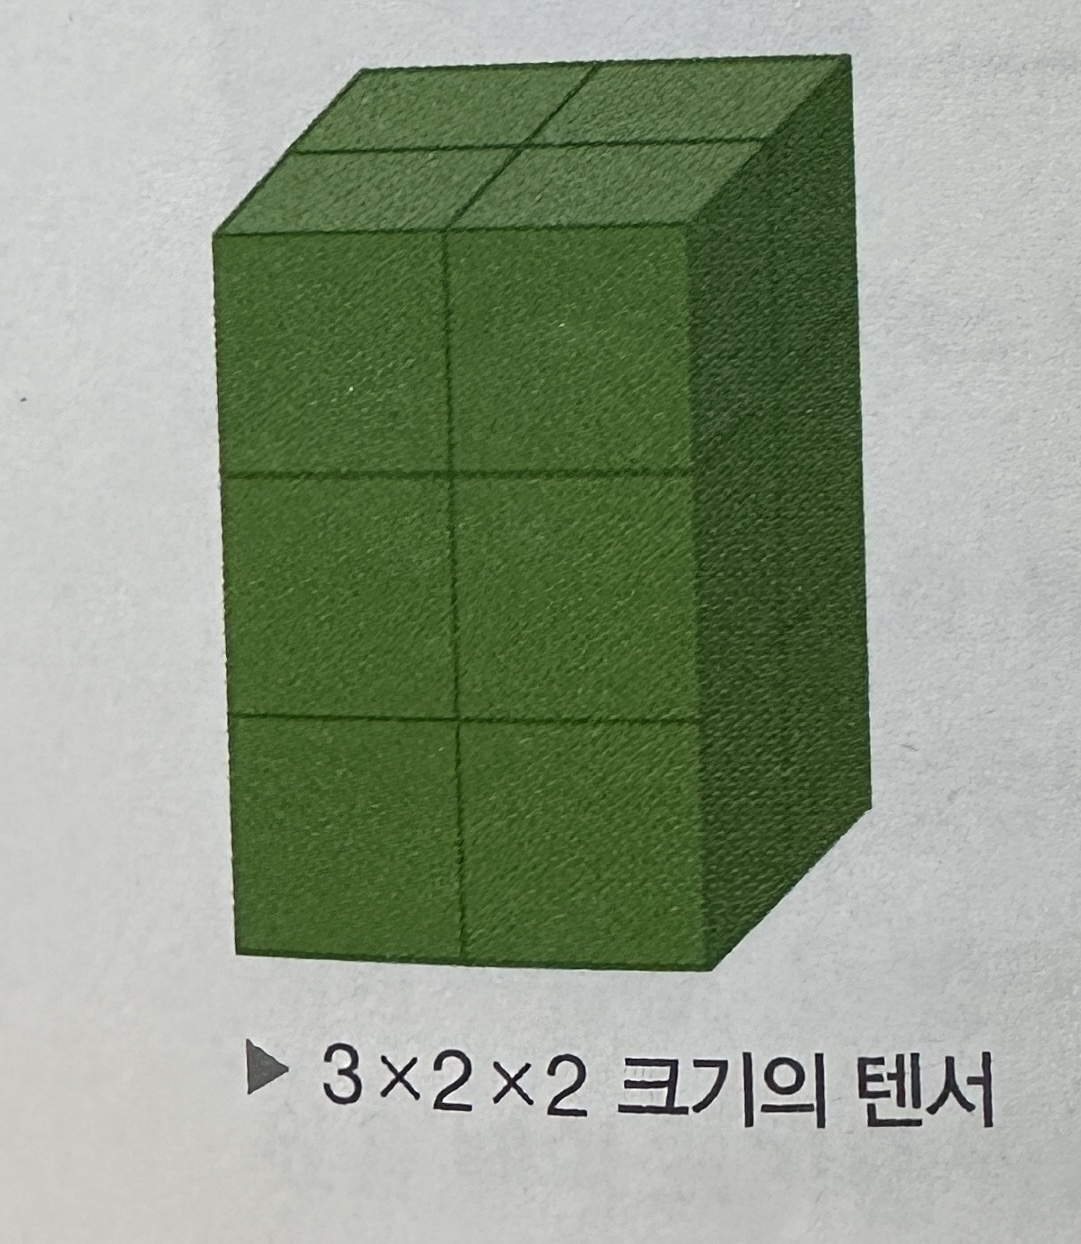

이 텐서의 첫 번째 차원의 0번 인덱스만 잘라내고(슬라이싱) 싶다면 다음과 같이 코드로 구현할 수 있습니다.

In [ ]:
# 첫 번째 차원의 0번 인덱스만 잘라내자
print(x[0])

tensor([[1., 2.],
        [3., 4.]])


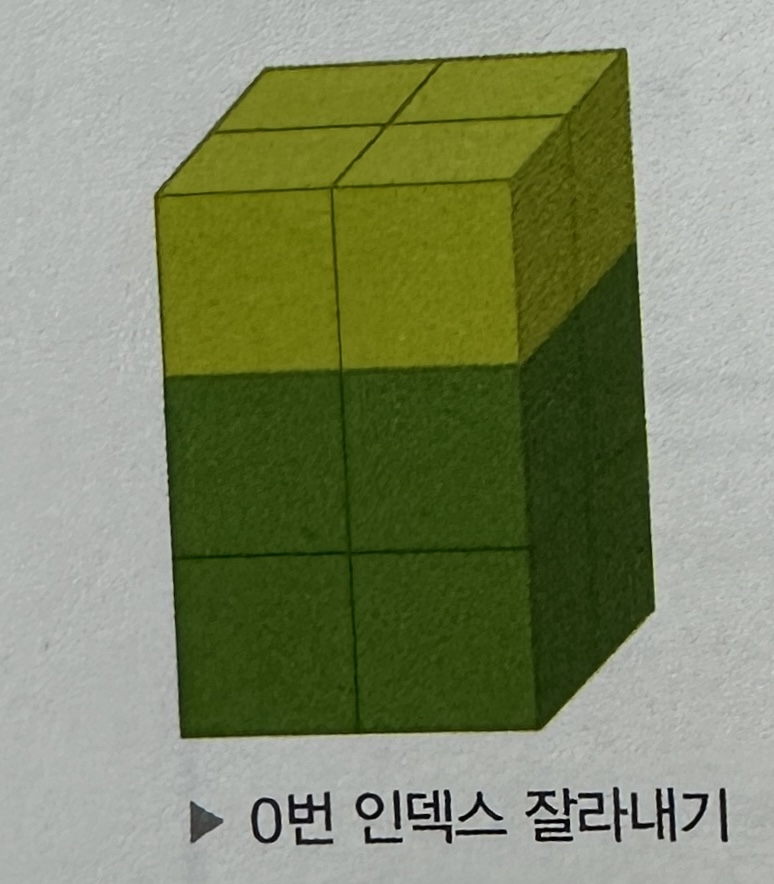

중간 차원을 잘라내고 싶다면 콜론(:)기호를 사용하면 됩니다.


In [ ]:
print(x[:,0])

tensor([[ 1.,  2.],
        [ 5.,  6.],
        [ 9., 10.]])


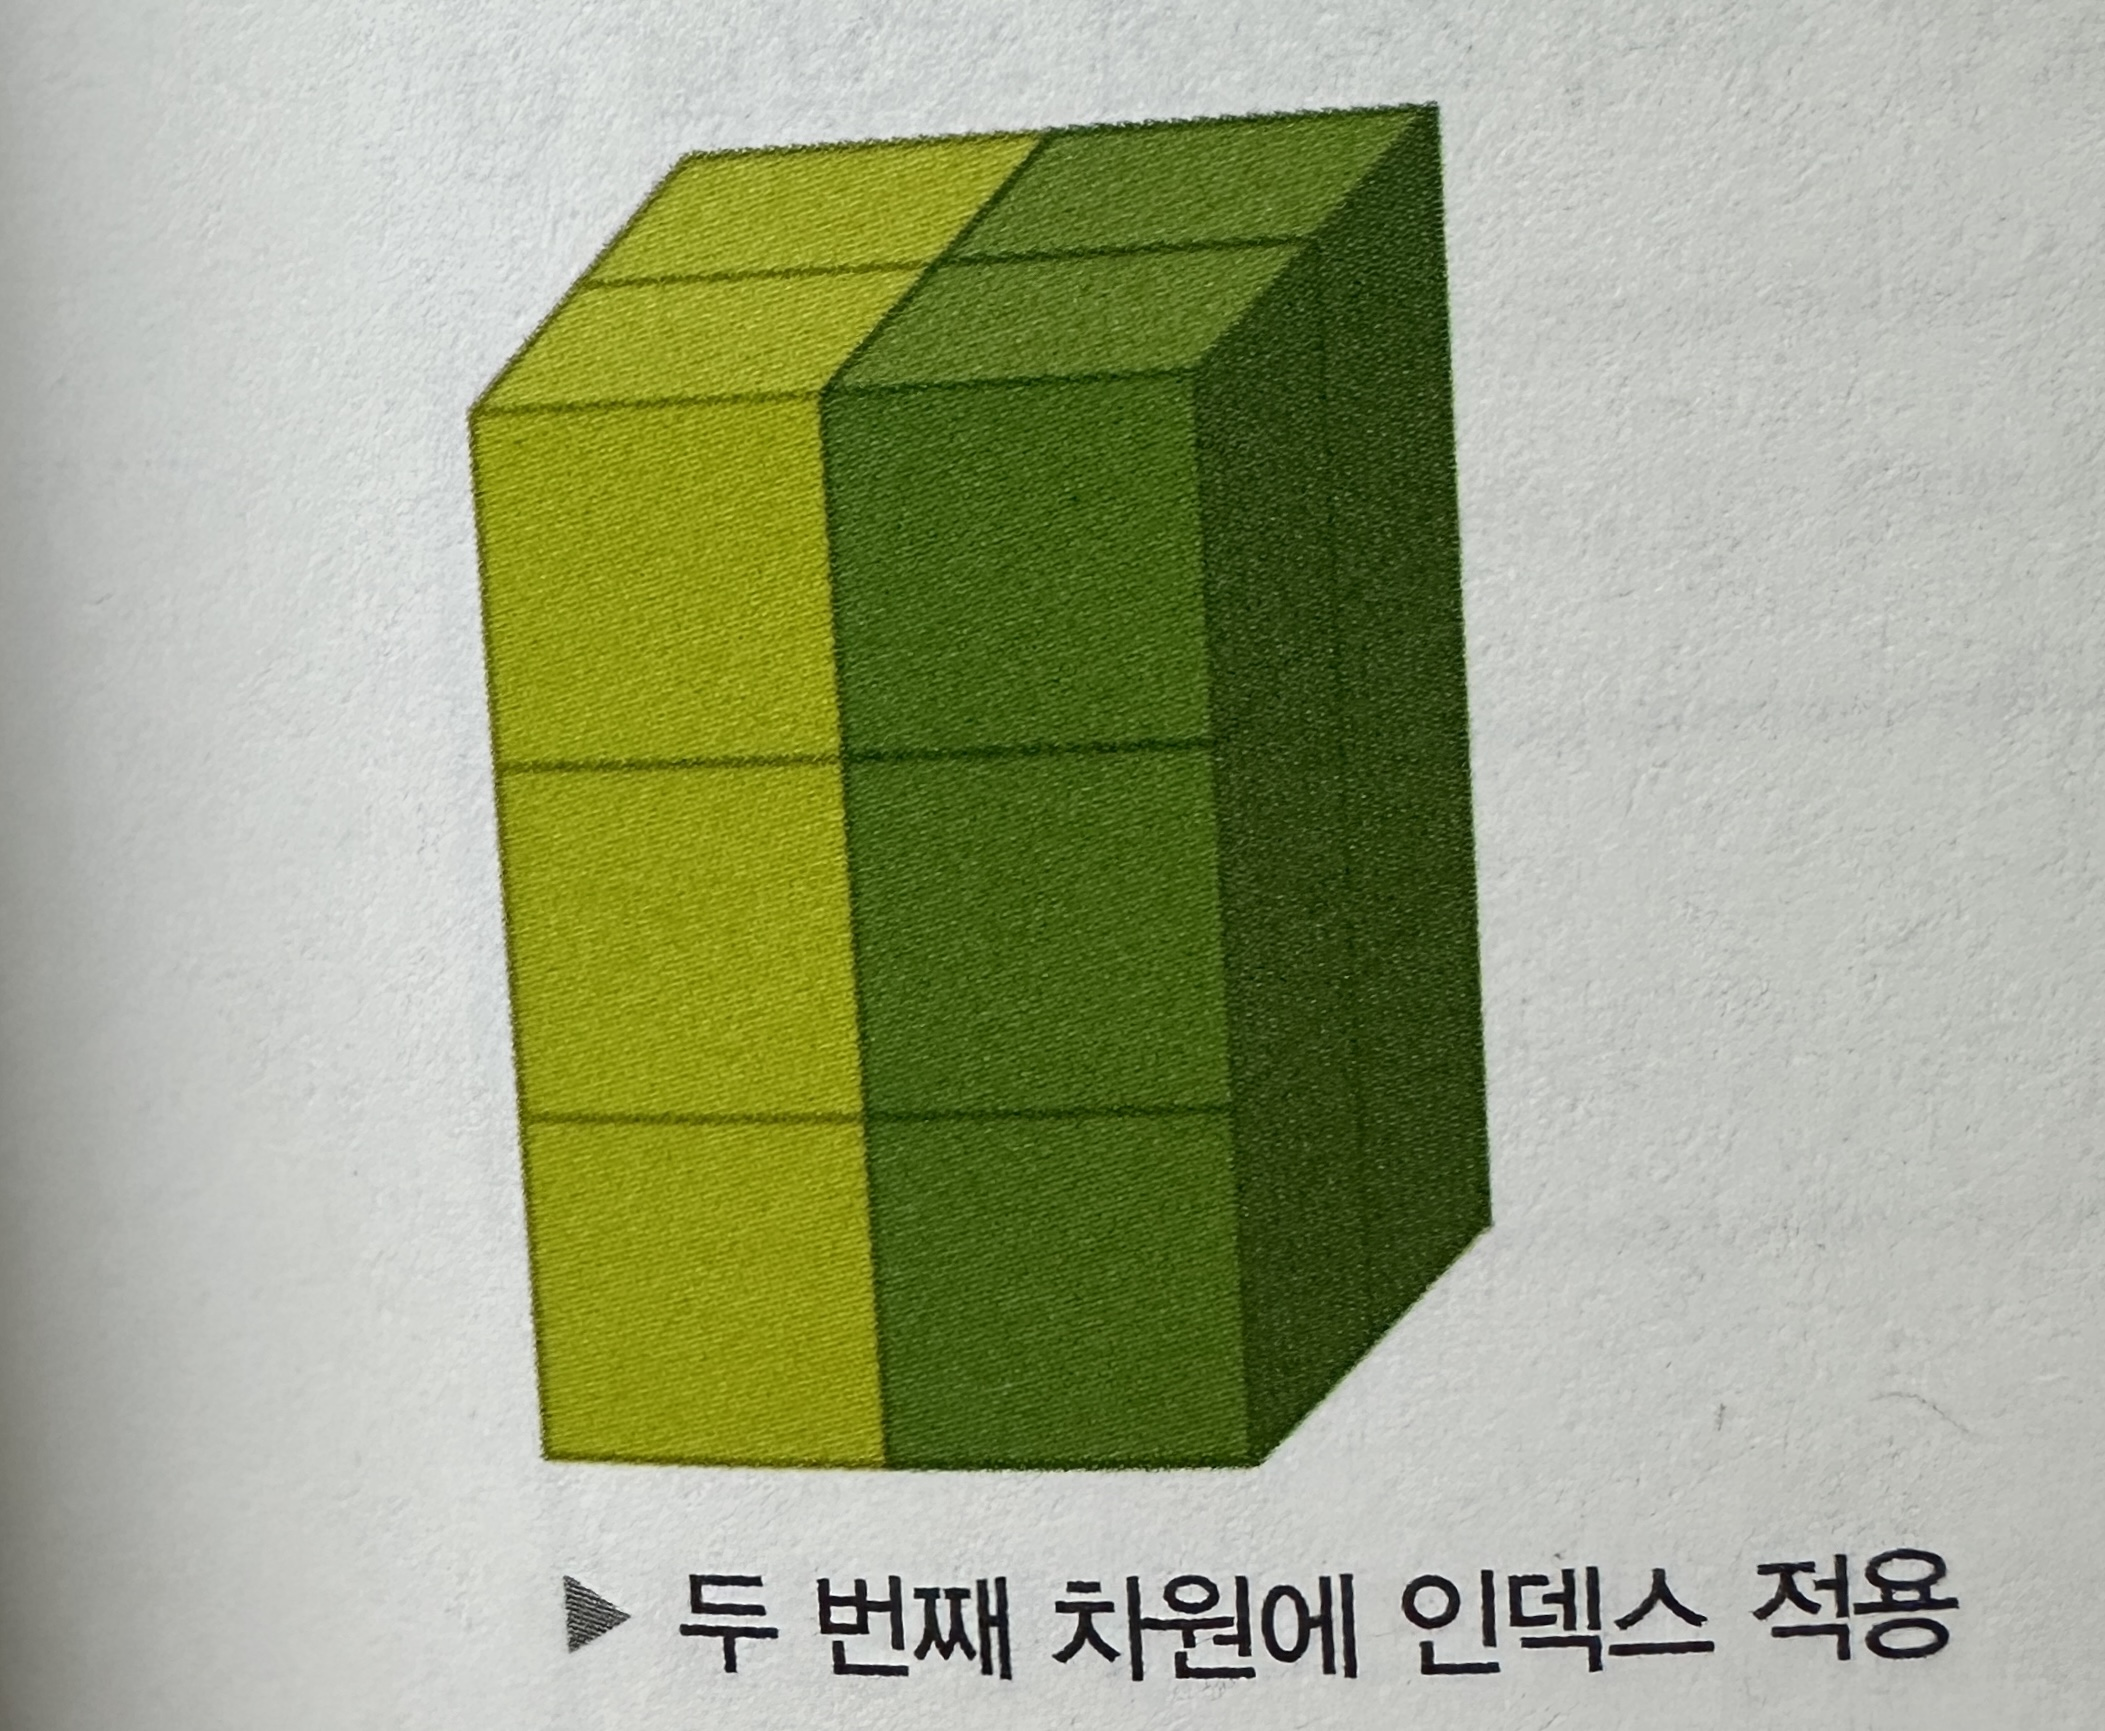

In [ ]:
print(x[1:2,1:,:])

tensor([[[7., 8.]]])


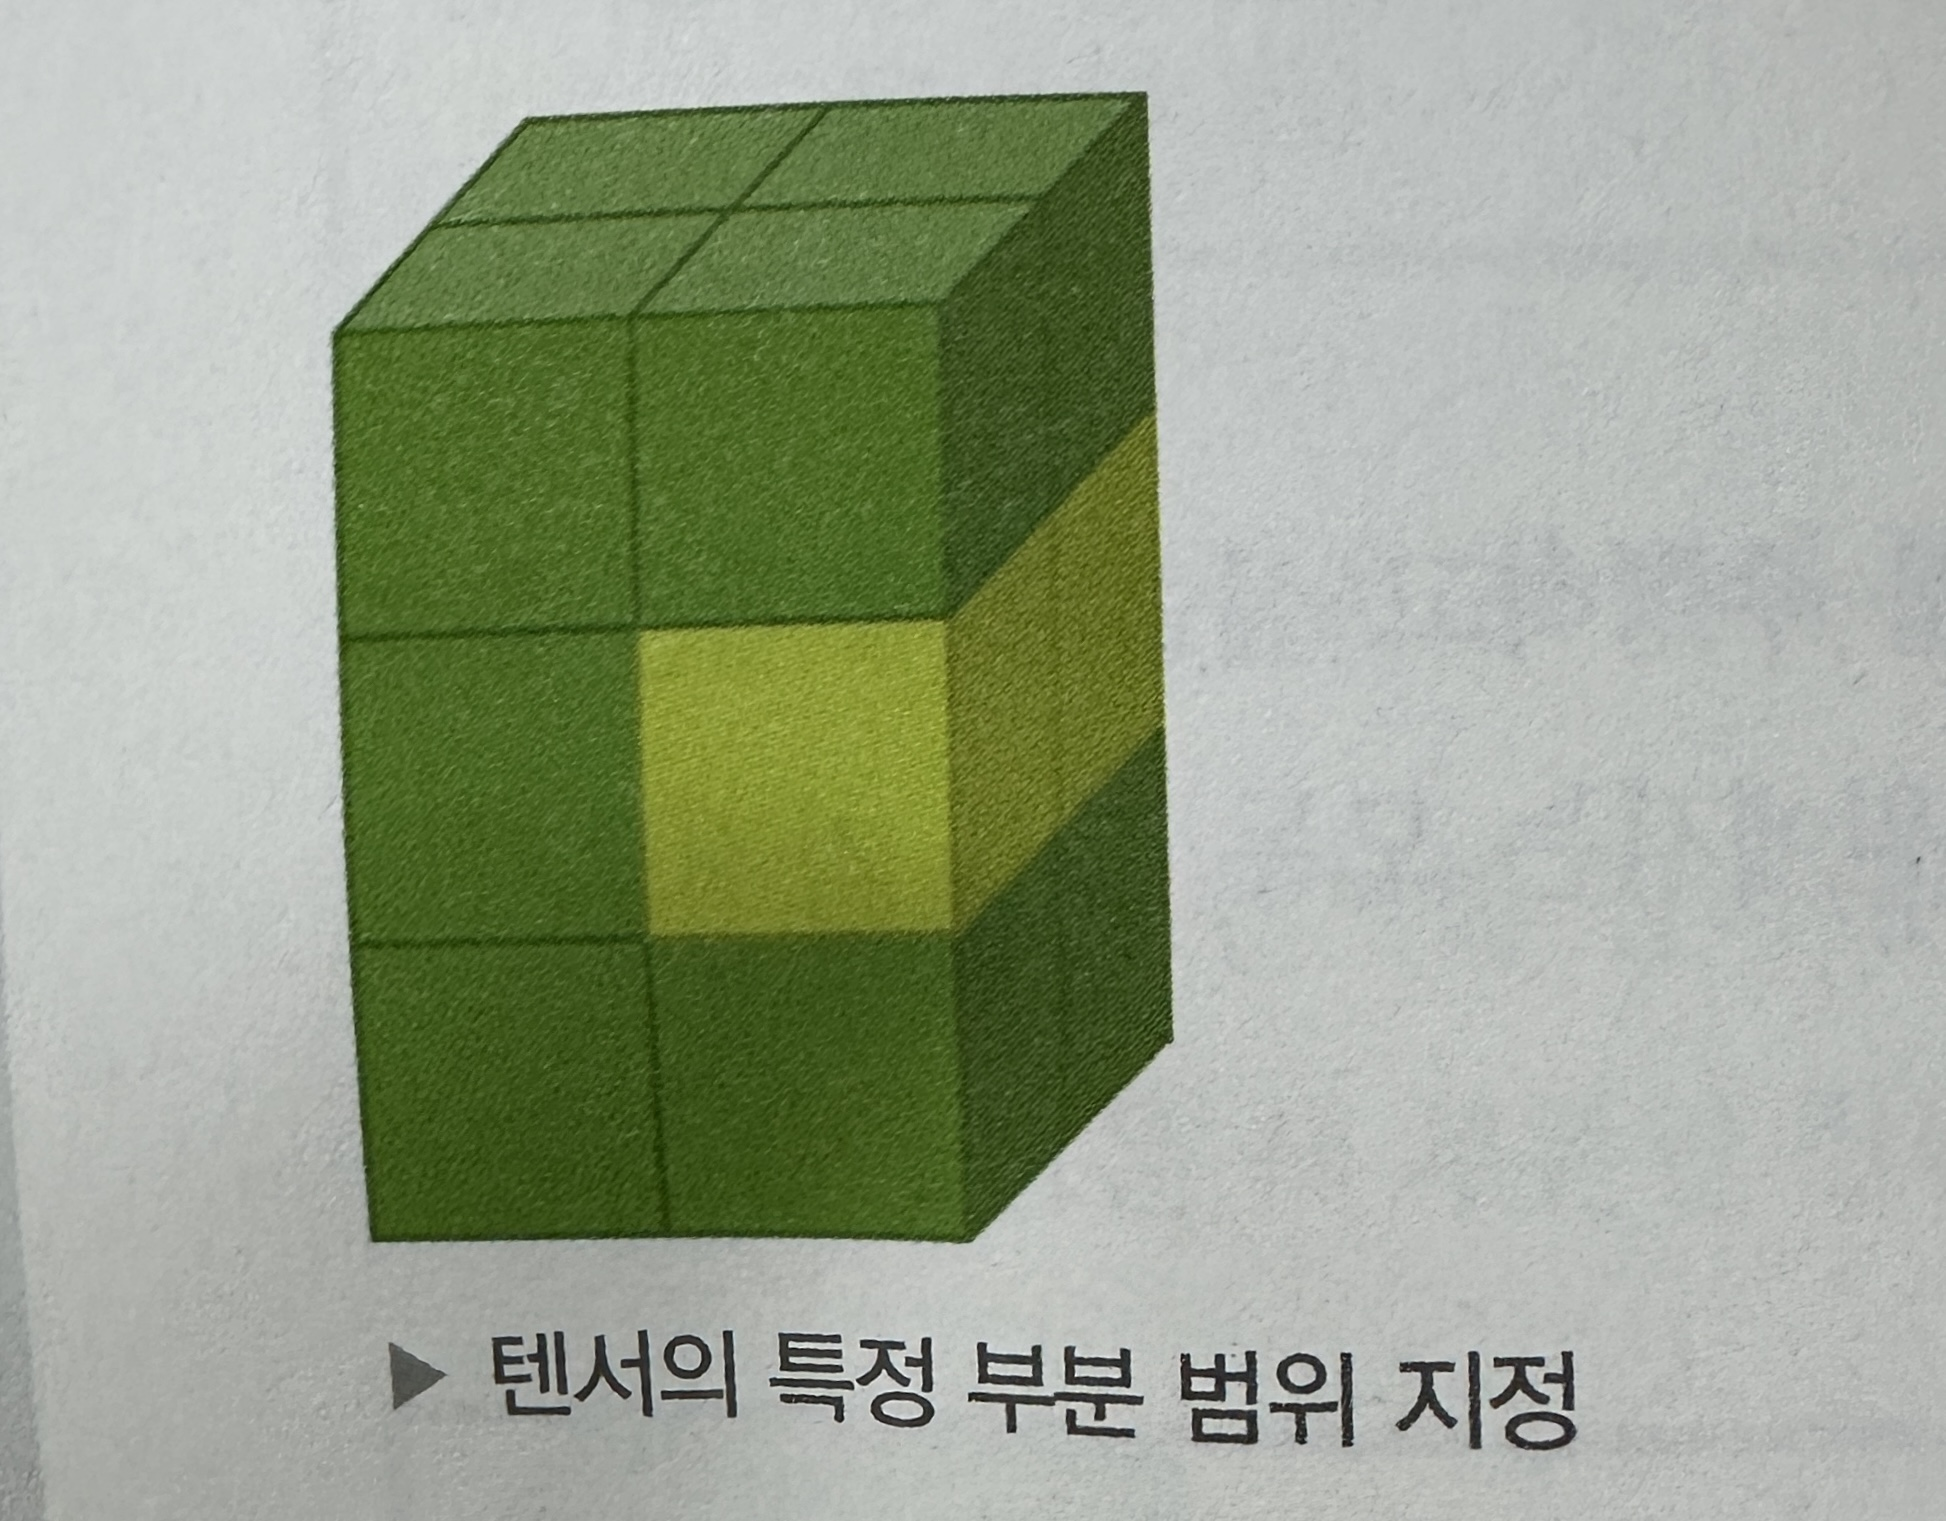

### Split()

- 텐서를 특정 차원에 대해서 **원하는 크기**로 잘라줍니다.

In [ ]:
x=torch.FloatTensor(10,4)
print(x)

tensor([[1.3413e-20, 0.0000e+00, 0.0000e+00, 0.0000e+00],
        [2.7074e+23, 3.0304e+35, 1.4226e-13, 6.2608e+22],
        [4.7428e+30, 7.7781e+31, 1.8515e+28, 6.8794e+11],
        [2.7253e+20, 3.0866e+29, 1.1824e+22, 7.0976e+22],
        [1.8515e+28, 4.1988e+07, 3.0357e+32, 7.7491e+26],
        [3.0357e+32, 6.3828e+28, 1.4603e-19, 1.8617e+25],
        [1.6212e-19, 1.8617e+25, 7.9438e+08, 3.2604e-12],
        [7.4086e+28, 1.9838e+29, 4.3218e+27, 4.7423e+30],
        [2.2856e+20, 3.2607e-12, 7.4086e+28, 3.1740e+30],
        [1.8545e+25, 1.7539e+19, 1.6635e+22, 1.0894e+27]])


In [ ]:
#  첫 번째 차원의 크기가 4가 되도록 텐서를 등분한 후에 각각의 등분된 텐서의 크기를 출력
Splits=x.split(4,dim=0)

for s in Splits:
  print(s.size())


torch.Size([4, 4])
torch.Size([4, 4])
torch.Size([2, 4])


In [ ]:
#  첫 번째 차원의 크기가 4가 되도록 텐서를 등분한 후에 각각의 등분된 텐서의 크기를 출력
Splits=x.split(2,dim=1)

for s in Splits:
  print(s.size())


torch.Size([10, 2])
torch.Size([10, 2])


### chuck()

- 크기에 상관 없이 원하는 계수로 나눕니다.

In [ ]:
x=torch.FloatTensor(8,4)
# 첫 번째 차원의 크기 8을 최대한 같은 크기로 3등분
chunks=x.chunk(3,dim=0)

for c in chunks:
  print(c.size())

torch.Size([3, 4])
torch.Size([3, 4])
torch.Size([2, 4])


### index_select()

- 특정 차원에서 원하는 인덱스의 값만 취하는 함수


In [ ]:
x=torch.FloatTensor([[[1,2],
                      [3,4]],
                     [[5,6],
                      [7,8]],
                     [[9,10],
                      [11,12]]])
print(x.size())

torch.Size([3, 2, 2])


In [ ]:
# 정수형으로 범위 지정을 위해 LongTensor 사용
indice=torch.LongTensor([2,1])

y=x.index_select(dim=0,index=indice)
print(y)

tensor([[[ 9., 10.],
         [11., 12.]],

        [[ 5.,  6.],
         [ 7.,  8.]]])


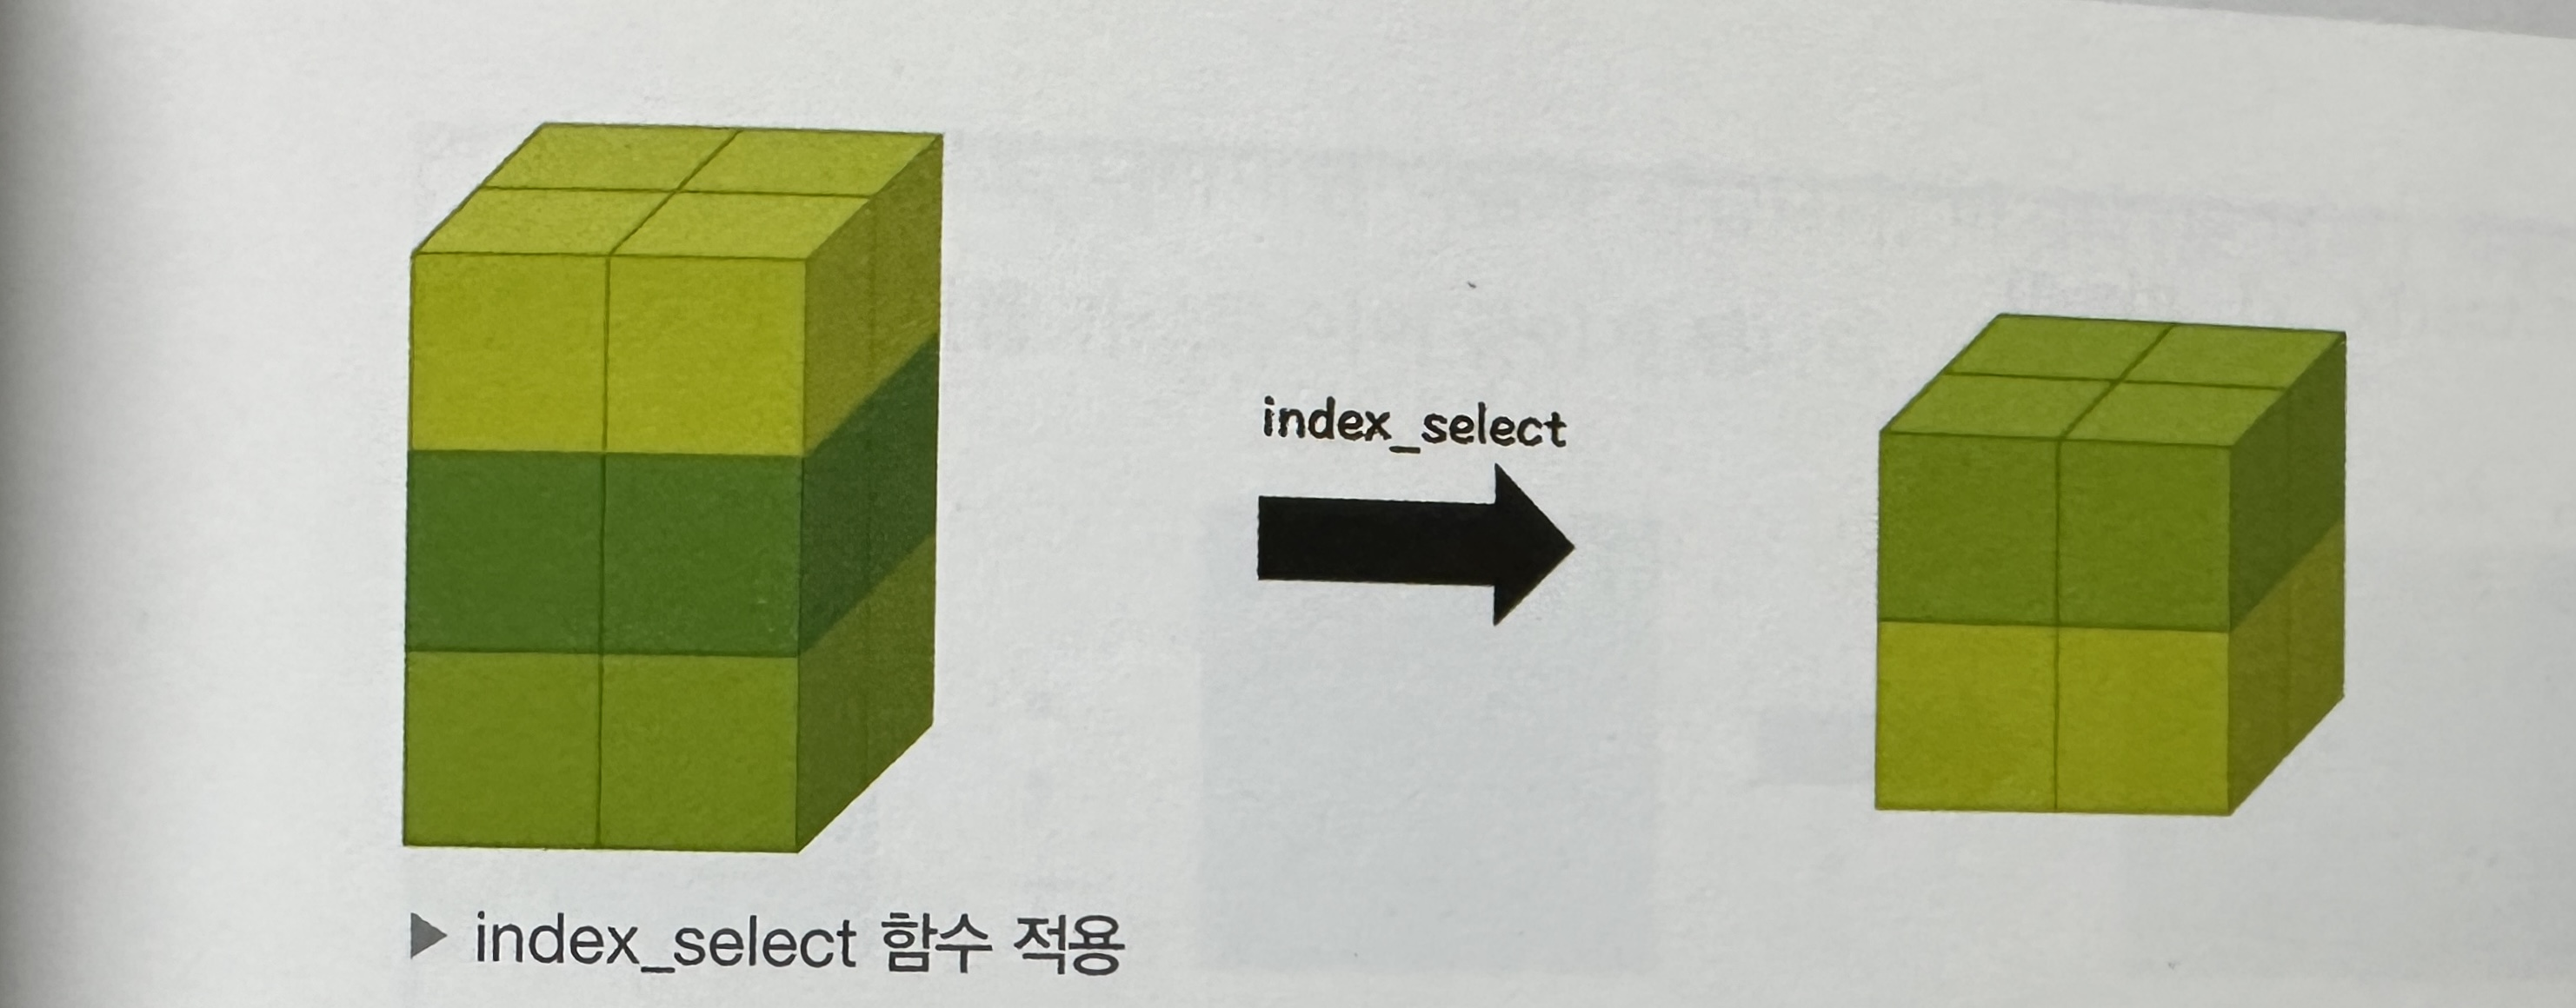

### Concatenate():cat()
- 차원의 크기가 같은 텐서를 합쳐서 하나의 텐서로 만듭니다.

In [ ]:
x=torch.FloatTensor([[1,2,3],
                     [4,5,6],
                     [7,8,9]])
y=torch.FloatTensor([[10,11,12],
                     [13,14,15],
                     [16,17,18]])
print(x.size(),y.size())


torch.Size([3, 3]) torch.Size([3, 3])


In [ ]:
z=torch.cat([x,y],dim=0)
print(z.size())

torch.Size([6, 3])


위 과정을 그림으로 나타내면 다음과 같습니다. 첫 번째 차원(dim=0)은 텐서의 세로축을 의미하므로 세로로 두 텐서를 이어 붙이게 됩니다.

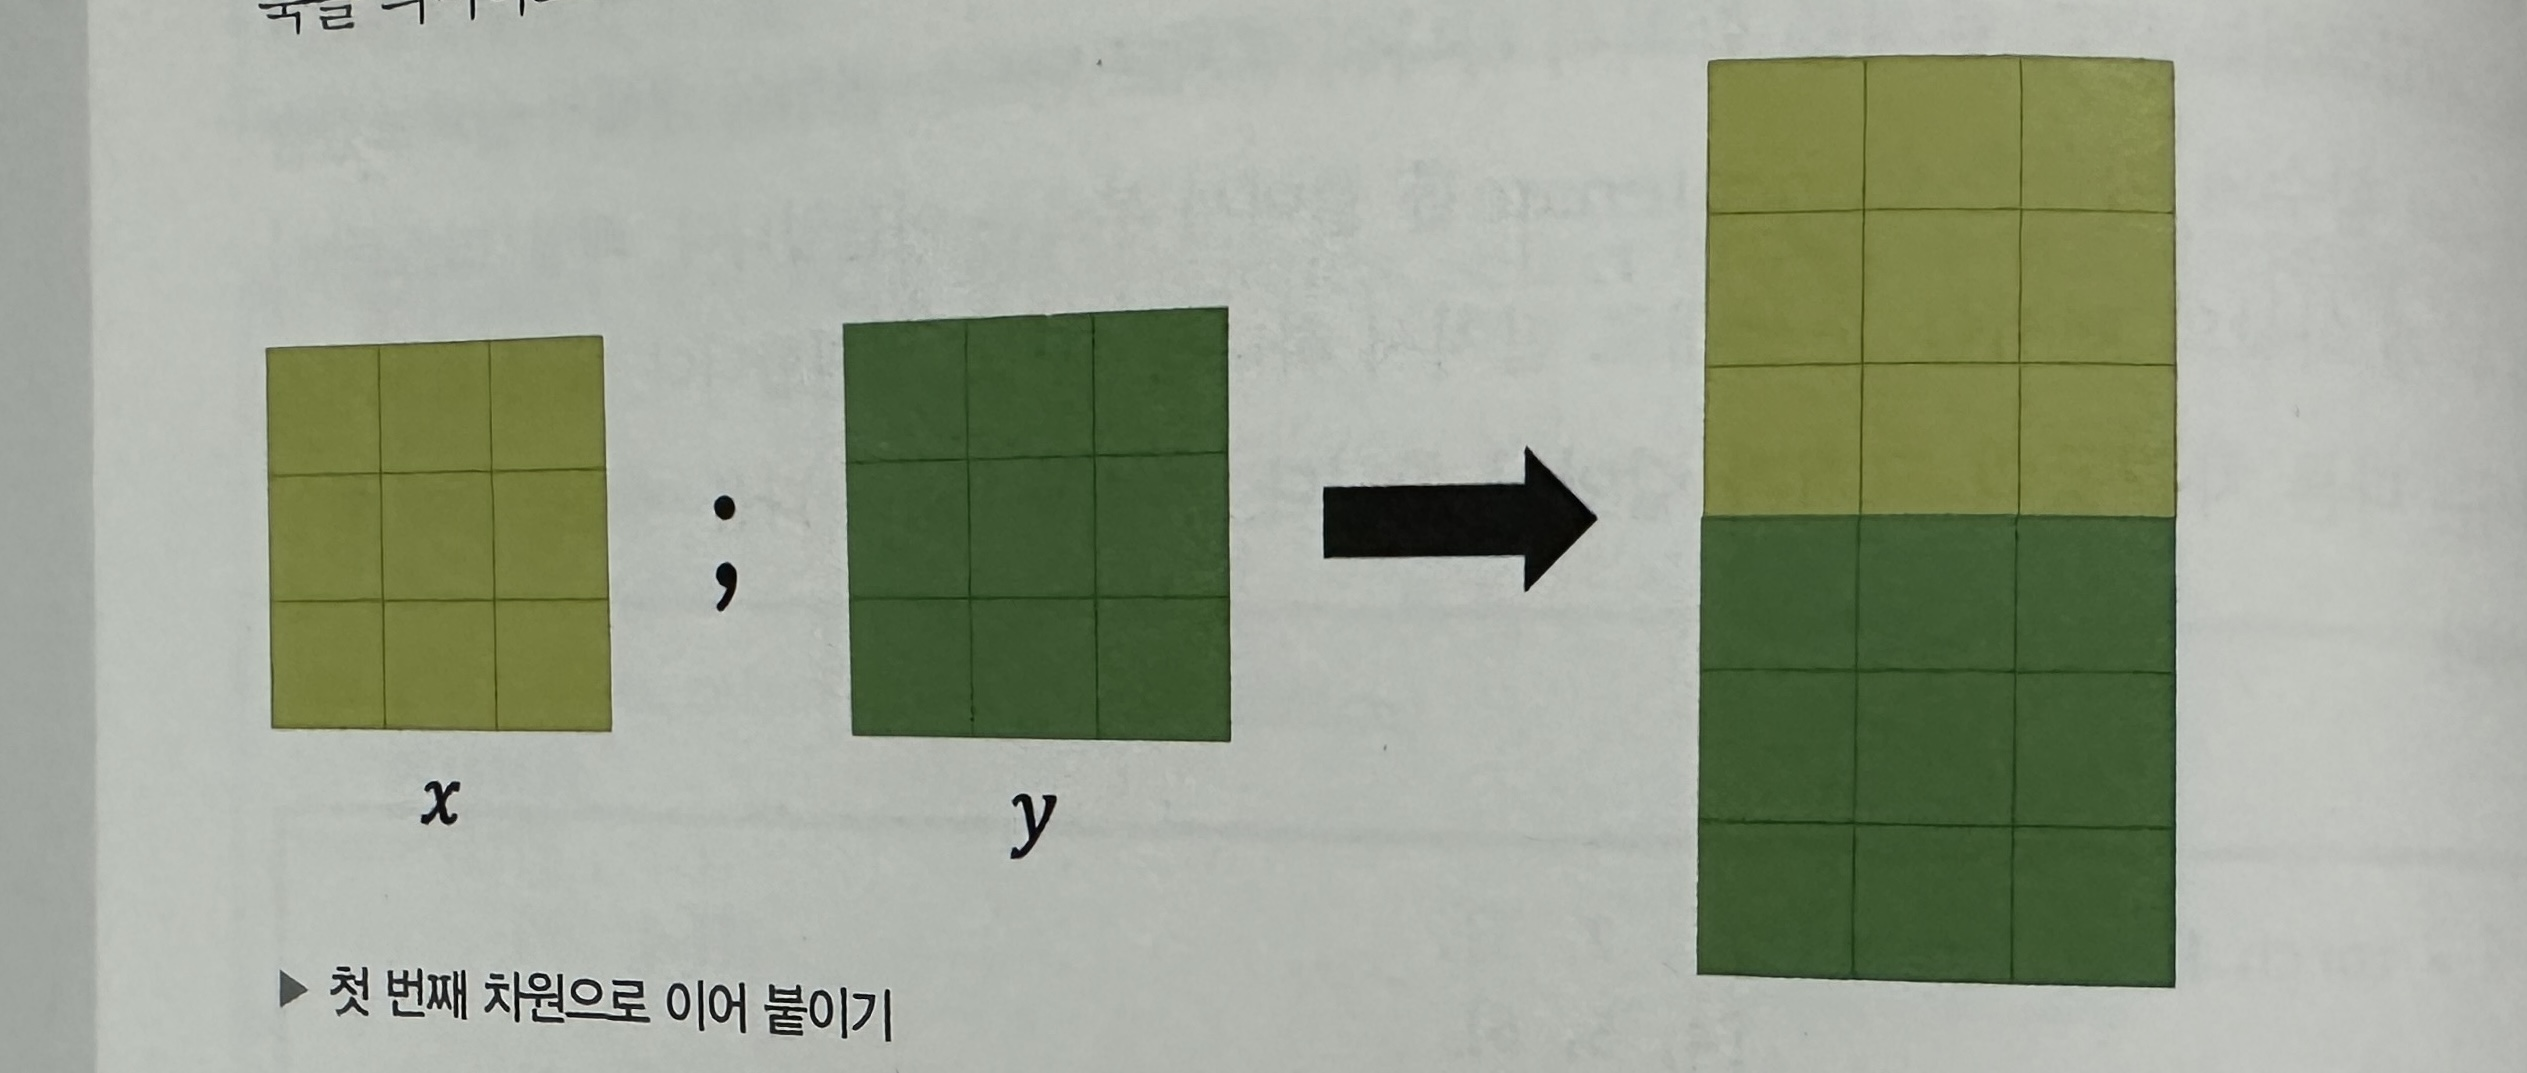

In [ ]:
z=torch.cat([x,y],dim=-1)
print(z.size())

torch.Size([3, 6])


마지막(두 번째)차원은 가로축을 의미하므로 두 텐서를 가로로 이어 붙이게 됩니다.

### Stack()
- 새로운 차원을 만든 뒤에 이어 붙이기를 수행

In [ ]:
z=torch.stack([x,y])
print(z.size())

torch.Size([2, 3, 3])


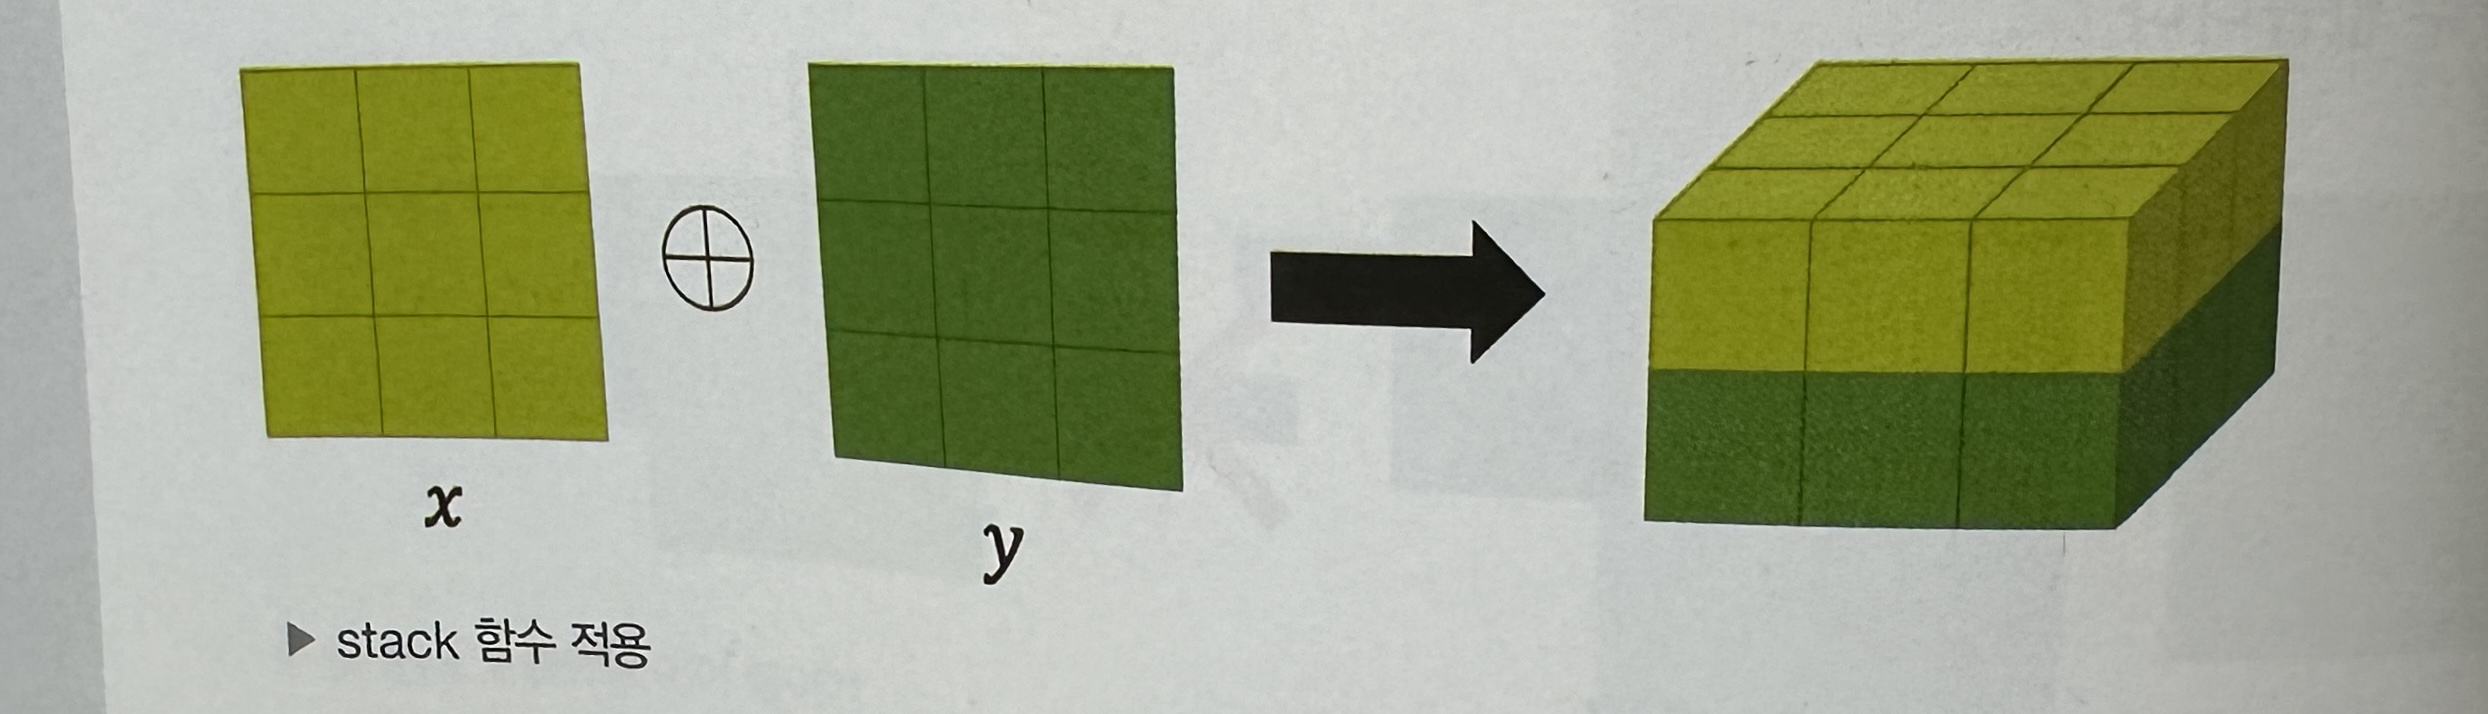

In [ ]:
z=torch.stack([x,y],dim=-1)
print(z.size())

tensor([[[ 1., 10.],
         [ 2., 11.],
         [ 3., 12.]],

        [[ 4., 13.],
         [ 5., 14.],
         [ 6., 15.]],

        [[ 7., 16.],
         [ 8., 17.],
         [ 9., 18.]]])
torch.Size([3, 3, 2])


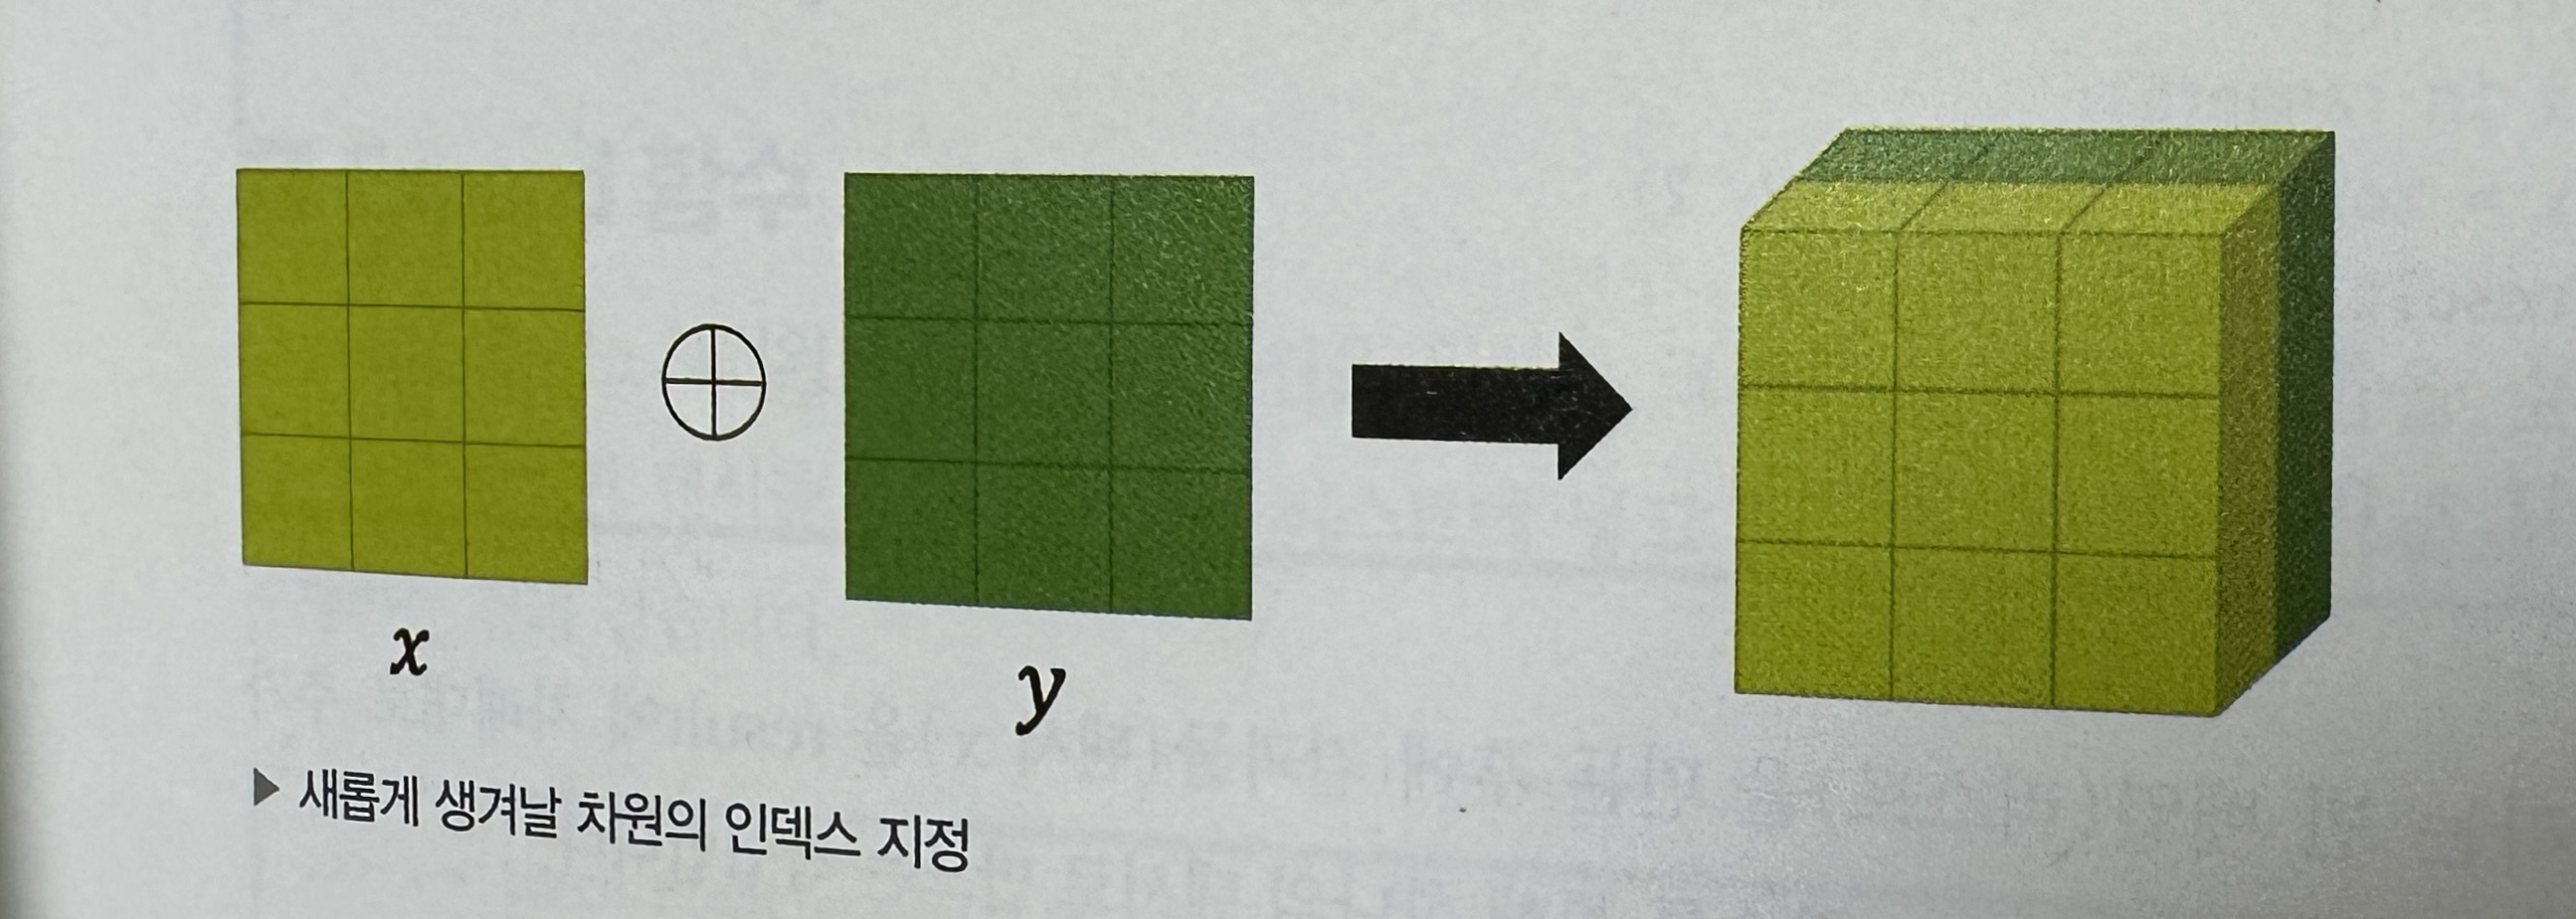

In [ ]:
d=0
#z=torch.stack([x,y],dim=d)
z=torch.cat([x.unsqueeze(d),y.unsqueeze(d)],dim=d)
print(x.unsqueeze(d).size())
print(y.unsqueeze(d).size())
print(z.size())

torch.Size([1, 3, 3])
torch.Size([1, 3, 3])
torch.Size([2, 3, 3])


cat()나 stack()는 여러 이터레이션(iteration)을 돌며 반복되는 작업을 수행한 후 반복 작업의 결과물을 하나로 합치는데 사용됩니다.

In [ ]:
result=[]
for i in range(5):
  x=torch.FloatTensor(2,2)
  result+=[x]

result=torch.stack(result)
print(result.shape)

torch.Size([5, 2, 2])


### 유용한 함수들

### Expand()

- 차원의 크기가 1인 차원을 원하는 크기로 늘려주는 역할을 수행합니다.
-


In [ ]:
x=torch.FloatTensor([[[1,2]],
                     [[3,4]]])
print(x.size())

torch.Size([2, 1, 2])


In [ ]:
# 두 번째 차원의 크기가 1인 텐서가 존재할 때, 두 번째 차원의 크기를 3으로 늘림
y=x.expand(2,3,2)
print(y.size())

torch.Size([2, 3, 2])


In [ ]:
# cat()를 이용해 구현
y=torch.cat([x]*3,dim=1)
print(y.size())

torch.Size([2, 3, 2])


### randperm()

- randperm()는 랜덤 수열을 생성하는 파이토치 함수입니다.
- 1부터 해당 숫자까지의 **정수**를 임의의 순서로 텐서에 넣어 반환합니다.

In [ ]:
x=torch.randperm(10)
print(x)

tensor([0, 1, 4, 5, 9, 7, 3, 6, 8, 2])


### argmax()
-  함수 f의 출력값을 최대로 만드는  가장 큰  한 개의 값의 인덱스x값을 반환

In [ ]:
x=torch.randperm(3**3).reshape(3,3,-1)
print(x.size())
print(x)

torch.Size([3, 3, 3])
tensor([[[26, 24,  1],
         [ 8,  7,  0],
         [11,  5,  9]],

        [[12, 19, 23],
         [ 6, 21, 15],
         [18, 10,  4]],

        [[22, 13, 17],
         [ 3,  2, 25],
         [20, 14, 16]]])


### 행 안에서 비교
- dim=-1 (dim=2): x[i][j][0], x[i][j][1], x[i][j][2] 끼리 비교. 위 예시처럼 각 행 안에서 비교

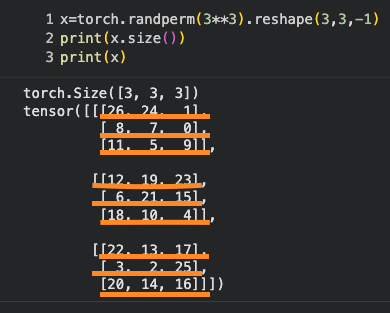

### 열 안에서 비교
- dim=1: x[i][0][k], x[i][1][k], x[i][2][k] 끼리 비교. 각 블록 안에서 세로(열) 방향으로 비교

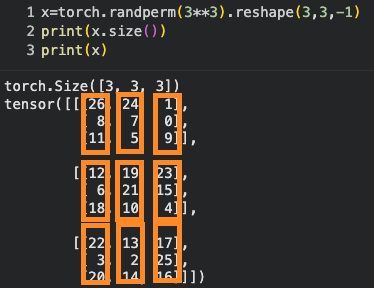

### 블록 사이에서 비교
- dim=0: x[0][j][k], x[1][j][k], x[2][j][k] 끼리 비교. 블록들을 가로질러 같은 위치끼리 비교

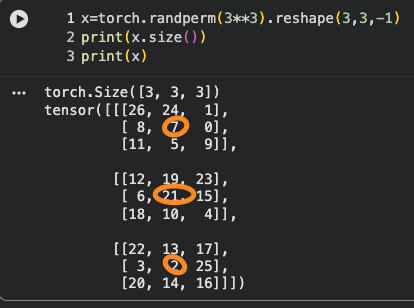

마지막 차원 방향으로 묶인 각 행(길이 3짜리 벡터)마다 최댓값의 인덱스를 구합니다.

In [ ]:
y=x.argmax(dim=-1)
print(y)

tensor([[0, 0, 0],
        [2, 1, 0],
        [0, 2, 0]])


### topk()
- 상위 k개 값과 인덱스를 모두 튜플 값으로 반환합니다.


In [ ]:
_, indices=torch.topk(x,k=2,dim=-1)
print(indices)
print(indices.size())

tensor([[[0, 1],
         [0, 1],
         [0, 2]],

        [[2, 1],
         [1, 2],
         [0, 1]],

        [[0, 2],
         [2, 0],
         [0, 2]]])
torch.Size([3, 3, 2])


### sort()
- 선언한 텐서 x를 원하는 차원 기준으로 정렬한 후 k개를 뽑아오는 파이토치 코드입니다.

In [ ]:
_,indices=torch.topk(x,k=2,dim=-1)
print(indices.shape)

torch.Size([3, 3, 2])


In [ ]:
target_dim=-1
values,indices=torch.topk(x,k=x.size(target_dim),largest=True)
print(values)

tensor([[[26, 24,  1],
         [ 8,  7,  0],
         [11,  9,  5]],

        [[23, 19, 12],
         [21, 15,  6],
         [18, 10,  4]],

        [[22, 17, 13],
         [25,  3,  2],
         [20, 16, 14]]])


결과물을 보면 마지막 차원 내에서만 내림차순으로 정렬되어 있는 것을 알 수 있습니다.

### masked_fill()

In [ ]:
x=torch.FloatTensor([i for i in range(3**2)]).reshape(3,-1)
print(x)
print(x.shape)

tensor([[0., 1., 2.],
        [3., 4., 5.],
        [6., 7., 8.]])
torch.Size([3, 3])


In [ ]:
# boolean 텐서를 만들어봅시다.
mask= x>4
print(mask)


tensor([[False, False, False],
        [False, False,  True],
        [ True,  True,  True]])


masked_fill()를 수행한다면 4보다 큰 값을 갖는 요소들을 특정 값으로 치환할 수 있게 됩니다.

4보다 큰 값을 모두 -1로 한 번에 치환

In [ ]:
y=x.masked_fill(mask,value=-1)
print(y)

tensor([[ 0.,  1.,  2.],
        [ 3.,  4., -1.],
        [-1., -1., -1.]])


### ones(), zeros()


In [ ]:
print(torch.ones(2,3))

tensor([[1., 1., 1.],
        [1., 1., 1.]])


In [ ]:
print(torch.zeros(2,3))

tensor([[0., 0., 0.],
        [0., 0., 0.]])


ones_like()와 zeros_like()를 통해서 특정 텐서와 같은 크기의 0 또는 1 텐서를 만들 수 있습니다.

In [ ]:
x=torch.FloatTensor([[1,2,3],
                     [4,5,6]])
print(x.size())

print(torch.ones_like(x))

print(torch.zeros_like(x))

torch.Size([2, 3])
tensor([[1., 1., 1.],
        [1., 1., 1.]])
tensor([[0., 0., 0.],
        [0., 0., 0.]])
